In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from scipy import constants
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

<hr style="border: 5px solid #000;">

# Espectro de emisión del Hg
(Nos quedamos con la medición 2)

**Notación:**

m: medición \
p: picos \
c: corrientes

In [2]:
# Leemos el archivo con los datos
Hg_m2 = pd.read_csv("Hg.csv",sep=',',skiprows=1,header=None,dtype='float',usecols=[0,1])

# Imprimimos los datos
Hg_m2

,0,1
0,350.0,3.300000e-07
1,352.0,3.300000e-07
2,354.0,3.300000e-07
3,356.0,3.300000e-07
4,358.0,3.300000e-07
...,...,...
121,592.0,3.300000e-07
122,594.0,3.300000e-07
123,596.0,3.300000e-07
124,598.0,3.300000e-07


In [3]:
# Nombramos las columnas
Hg_m2.columns = (["x","y"])

# Guardamos los valores de cada columna en listas para graficar más fácil
Hg_m2_onda = Hg_m2["x"].values
Hg_m2_corriente = Hg_m2["y"].values

**Hacemos una gráfica inicial del espectro:**

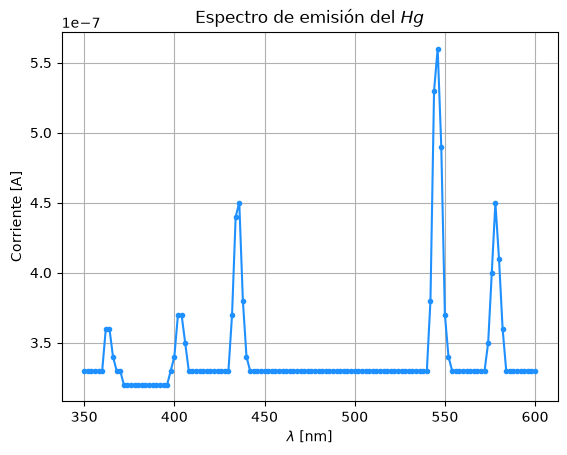

In [4]:
plt.plot(Hg_m2_onda,Hg_m2_corriente,'.-',c='dodgerblue')
plt.title(r'Espectro de emisión del $Hg$')
plt.xlabel(r'$\lambda$ [nm]'), plt.ylabel(r'Corriente [A]')
plt.grid()

**Buscamos los picos** (de izquiera a derecha) **y los graficamos para confirmar:**

In [5]:
# Ponemos a mano los rangos en donde se encuentra cada pico (en ÍNDICES, no en el valor de lambda)
rangos = [(0,25), (25,40), (40,75), (75,100), (100,None)]

Hg_m2_p = [] # picos
Hg_m2_c = [] # corriente que le corresponde a ese pico

for i,j in rangos:
    Hg_m2_c.append( max(Hg_m2_corriente[i:j]) )
    Hg_m2_p.append( Hg_m2_onda[i + np.argmax(Hg_m2_corriente[i:j])] )
    
for i, (j,k) in enumerate(zip(Hg_m2_p,Hg_m2_c), start=1):
    print(f'Pico {i} = {j} nm\n Corriente ({i}) = {k}')

Pico 1 = 362.0 nm
 Corriente (1) = 3.6e-07
Pico 2 = 402.0 nm
 Corriente (2) = 3.7e-07
Pico 3 = 436.0 nm
 Corriente (3) = 4.5e-07
Pico 4 = 546.0 nm
 Corriente (4) = 5.6e-07
Pico 5 = 578.0 nm
 Corriente (5) = 4.5e-07


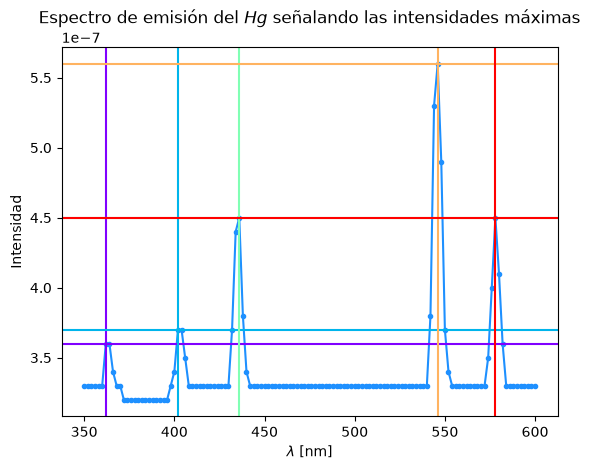

In [6]:
# Gráfica del espectro
plt.plot(Hg_m2_onda,Hg_m2_corriente,'.-',c='dodgerblue')
plt.title(r'Espectro de emisión del $Hg$ señalando las intensidades máximas')
plt.xlabel(r'$\lambda$ [nm]'), plt.ylabel(r'Intensidad')

# Creamos un grupo de varios colores para distinguir cada pico
n = 5
colores = plt.cm.rainbow(np.linspace(0,1,n))

# Señalamiento de cada pico
for i,j, k in zip(Hg_m2_p,Hg_m2_c, colores):
    plt.axvline(i, color=k), plt.axhline(j, color=k)

Cada pico calculado está bien :)

**Gráfica chida para el reporte y la expo:**

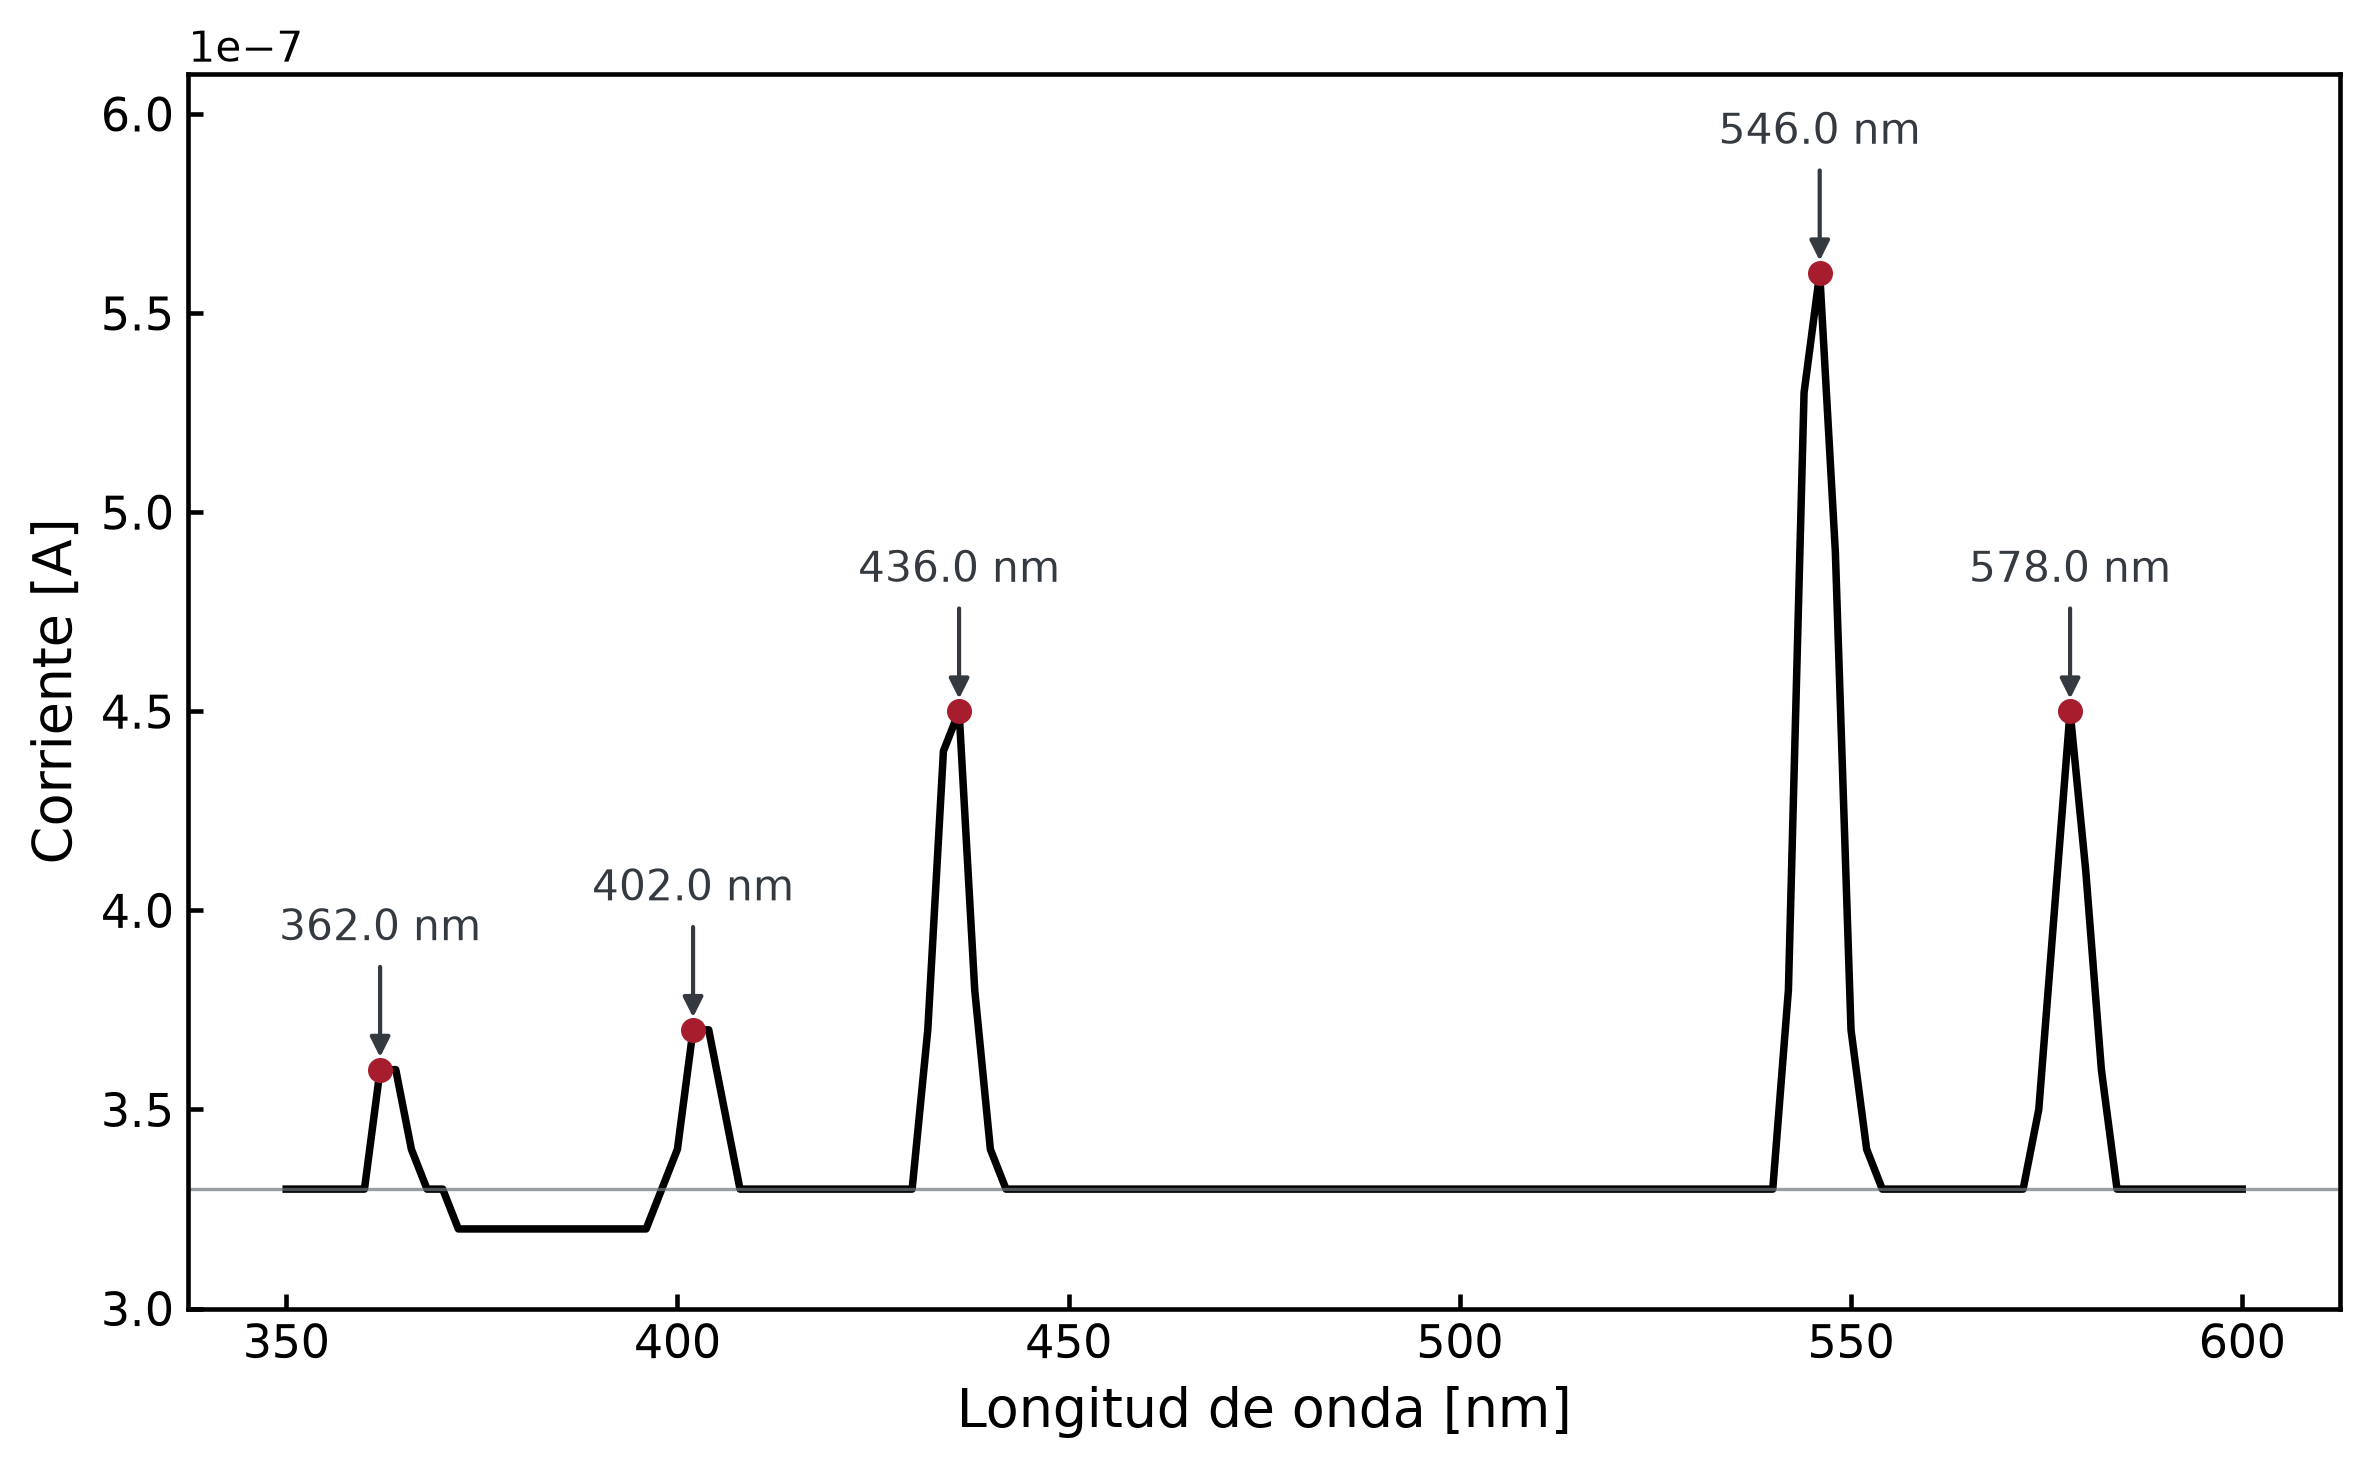

In [7]:
fig, ax = plt.subplots(figsize=(8,5),dpi=300)

# Curva principal
ax.plot(Hg_m2_onda,Hg_m2_corriente,color="black",linewidth=1.8)
# Línea base
ax.axhline(3.3e-7,color="#6C757D",linewidth=0.8,alpha=0.7)

# Marcadores y etiquetas de los picos
for i,j in zip(Hg_m2_p,Hg_m2_c):
    # Punto del pico
    ax.plot(i,j,marker="o",markersize=5,color="#A61E2D",zorder=3)
    # Flecha y longitud de onda
    ax.annotate(fr"{i:.1f} nm",xy=(i,j),xytext=(i,j+0.3e-7),ha="center",va="bottom",fontsize=10,
                color="#343A40",arrowprops=dict(arrowstyle="-|>",color="#343A40",lw=1.0,shrinkA=2,shrinkB=3))

# Diseño de los ejes
ax.tick_params(direction="in",labelsize=11,width=1.1)
for borde in ax.spines.values():
    borde.set_linewidth(1.1)
ax.set_xlabel(r"Longitud de onda [nm]",fontsize=13)
ax.set_ylabel("Corriente [A]",fontsize=13)

# Rango de la gráfica
#ax.set_xlim(0,1)
ax.set_ylim(3e-7, 6.1e-7)

plt.tight_layout()
plt.show()

<hr style="border: 5px solid #000;">

# Potenciales de frenado
(Para cada **pico** que hemos encontrado, la fijamos en el monocromador y variamos el voltaje del fototubo para encontrar su voltaje de frenado)

In [8]:
# Estos son los valores que utilizamos:
long_onda = np.array([365, 403, 436, 546, 578]) # en nanómetros (nm)

c = constants.c
print('Valor de la velocidad de la luz en el vacío (c):',c,'m/s')

# Por lo tanto, las frecuencias son
frecuencias = c/(long_onda*1e-9)
print('y las frecuencias son:',frecuencias,'Hz')

Valor de la velocidad de la luz en el vacío (c): 299792458.0 m/s
y las frecuencias son: [8.21349200e+14 7.43901881e+14 6.87597381e+14 5.49070436e+14
 5.18672073e+14] Hz


<hr style="border: 2px solid #000;">

#### $\lambda_1 = 365 \text{ nm } \rightarrow \nu_1 = 8.21349200\times 10^{14} \text{ Hz}$

In [9]:
# Leemos el archivo con los datos
long1_m1 = pd.read_csv("Lambda_1-voltaje_corriente.csv",sep=',',skiprows=1,header=None,dtype='float',usecols=[0,1,2])

# Imprimimos los datos
long1_m1

,0,1,2
0,-3.0,0.276,2.700000e-08
1,-2.8,0.278,2.700000e-08
2,-2.6,0.279,2.700000e-08
3,-2.4,0.281,2.700000e-08
4,-2.2,0.282,2.700000e-08
5,-2.0,0.284,2.700000e-08
6,-1.8,0.286,2.700000e-08
7,-1.6,0.287,2.700000e-08
8,-1.4,0.289,2.700000e-08
9,-1.2,0.290,2.700000e-08


In [10]:
# Nombramos las columnas
long1_m1.columns = (["x","z","y"])

# Guardamos los valores de cada columna en listas para graficar más fácil
long1_m1_voltaje = long1_m1["x"].values
long1_m1_incVolt = long1_m1["z"].values
long1_m1_corriente = long1_m1["y"].values

**Hacemos una gráfica inicial de los datos obtenidos**

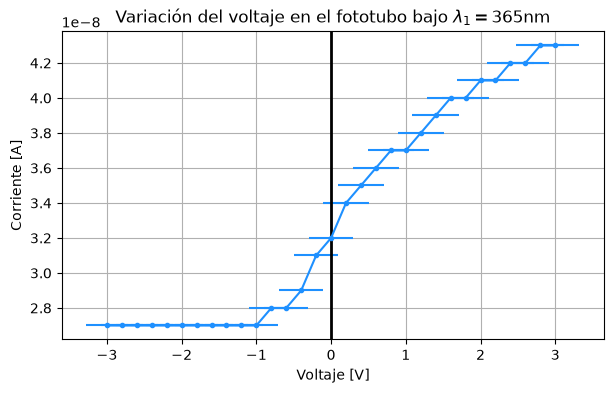

In [11]:
plt.figure(figsize=(7,4))

plt.errorbar(long1_m1_voltaje,long1_m1_corriente,xerr=long1_m1_incVolt,fmt='.-',c='dodgerblue')
plt.title(r'Variación del voltaje en el fototubo bajo $\lambda_1=365$nm')
plt.xlabel(r'Voltaje [V]'), plt.ylabel(r'Corriente [A]')
plt.axvline(x=0, color='black', linewidth=2)
plt.grid()

Buscamos el potencial de frenado como aquel voltaje en donde la corriente comienza a aumentar

In [12]:
for i in range( len(long1_m1_corriente) ):
    if long1_m1_corriente[i+1] > long1_m1_corriente[i]:
        indice = i+1
        print('El índice que corresponde al potencial de frenado es:',indice)
        print(f'Corriente = {long1_m1_corriente[indice]} A')
        print(f'Voltaje de frenado = {long1_m1_voltaje[indice]} ± {long1_m1_incVolt[indice]:.1f} V')
        break

El índice que corresponde al potencial de frenado es: 11
Corriente = 2.8e-08 A
Voltaje de frenado = -0.8 ± 0.3 V


**Gráfica "chida" para el reporte y la expo:**

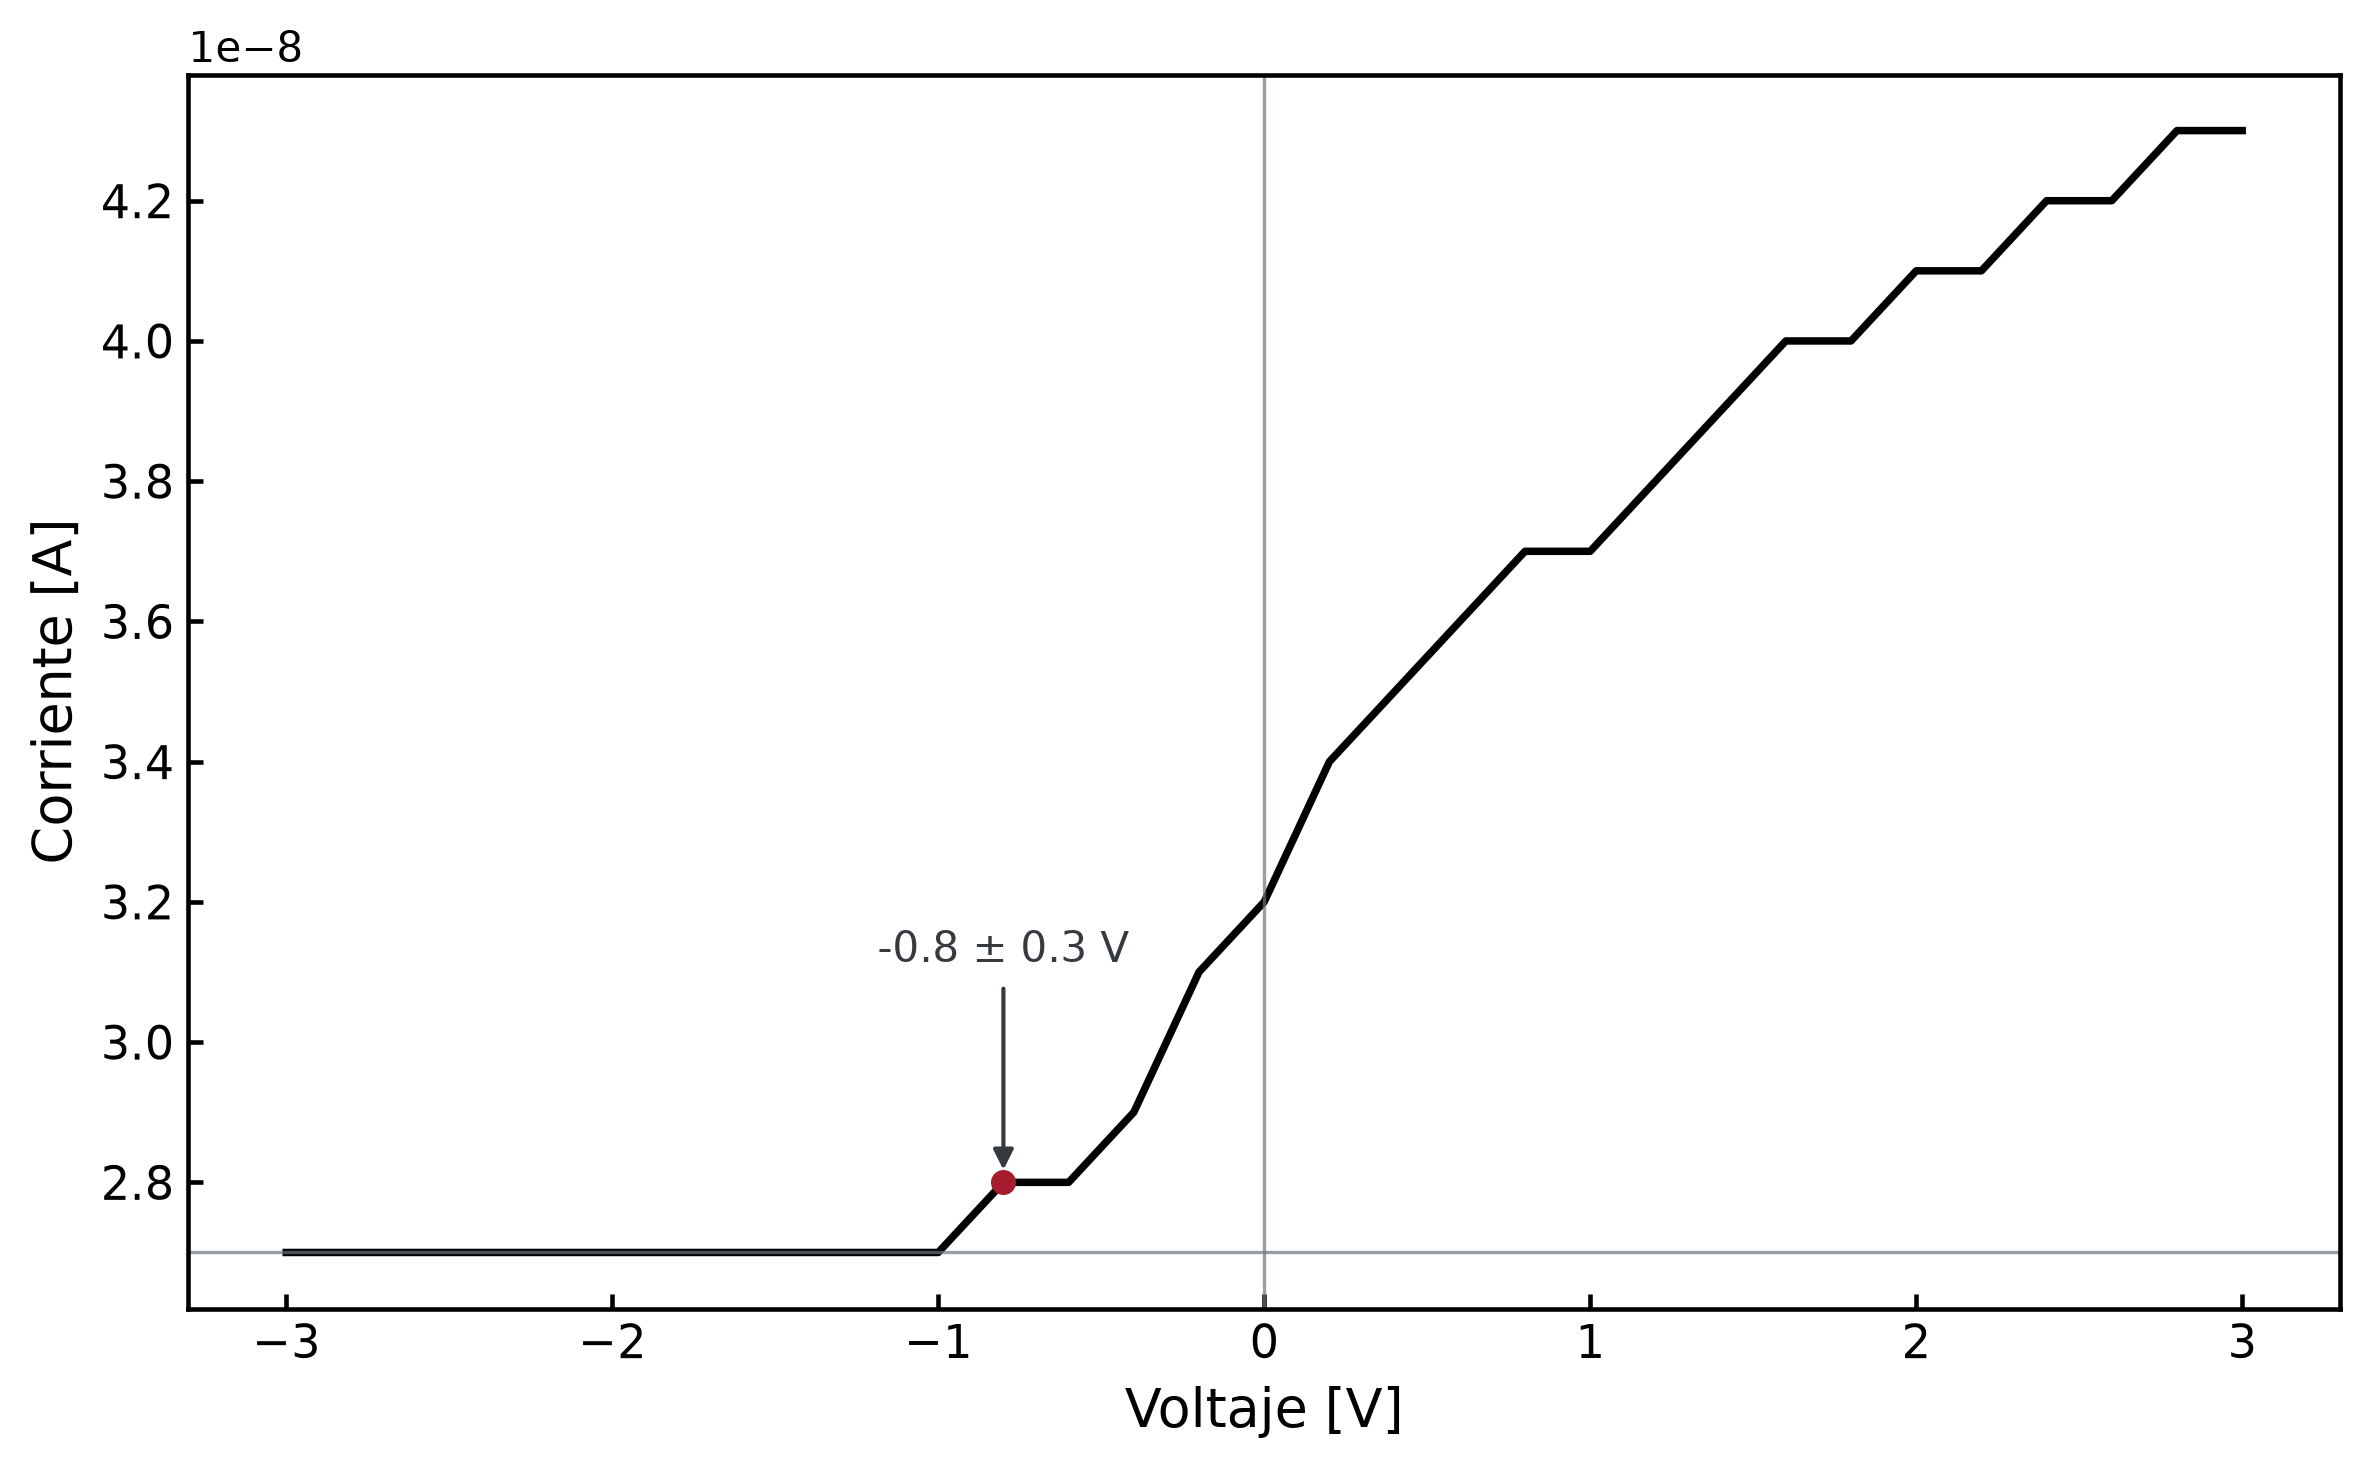

In [13]:
# PRESTAMOS ATENCIÓN PARA HACER REFERENCIA A LA LAMBDA Y EL ÍNDICE CORRECTO
x = long1_m1_voltaje[11]
inc = long1_m1_incVolt[11]
y = long1_m1_corriente[11]

fig, ax = plt.subplots(figsize=(8,5),dpi=300)

# Curva principal
ax.plot(long1_m1_voltaje,long1_m1_corriente,color="black",linewidth=1.8)

# LO QUE SIGUE YA ESTÁ AUTOMATIZADO
# Líneas base
ax.axhline(2.7e-8,color="#6C757D",linewidth=0.8,alpha=0.7)
ax.axvline(0,color="#6C757D",linewidth=0.8,alpha=0.7)

ax.plot(x,y,marker="o",markersize=5,color="#A61E2D",zorder=3)
ax.annotate(fr"{x:.1f} ± {inc:.1f} V",
                xy=(x,y),xytext=(x,y+0.3e-8),ha="center",va="bottom",fontsize=10,
                color="#343A40",arrowprops=dict(arrowstyle="-|>",color="#343A40",lw=1.0,shrinkA=2,shrinkB=3))

# Diseño de los ejes
ax.tick_params(direction="in",labelsize=11,width=1.1)
for borde in ax.spines.values():
    borde.set_linewidth(1.1)
ax.set_xlabel(r"Voltaje [V]",fontsize=13)
ax.set_ylabel("Corriente [A]",fontsize=13)

# Rango de la gráfica
#ax.set_xlim(0,1)
#ax.set_ylim(3e-7, 6.1e-7)

plt.tight_layout()
plt.show()

<hr style="border: 2px solid #000;">

#### $\lambda_2 = 403 \text{ nm } \rightarrow \nu_2 = 7.43901881\times 10^{14} \text{ Hz}$

In [14]:
# Leemos el archivo con los datos
long2_m1 = pd.read_csv("Lambda_2-voltaje_corriente.csv",sep=',',skiprows=1,header=None,dtype='float',usecols=[10,11,12])

# Imprimimos los datos
long2_m1

,10,11,12
0,-3.0,0.276,3.200000e-07
1,-2.8,0.278,3.200000e-07
2,-2.6,0.279,3.200000e-07
3,-2.4,0.281,3.200000e-07
4,-2.2,0.282,3.200000e-07
5,-2.0,0.284,3.200000e-07
6,-1.8,0.286,3.200000e-07
7,-1.6,0.287,3.200000e-07
8,-1.4,0.289,3.200000e-07
9,-1.2,0.290,3.300000e-07


In [15]:
# Nombramos las columnas
long2_m1.columns = (["x","z","y"])

# Guardamos los valores de cada columna en listas para graficar más fácil
long2_m1_voltaje = long2_m1["x"].values
long2_m1_incVolt = long2_m1["z"].values
long2_m1_corriente = long2_m1["y"].values

**Hacemos una gráfica inicial de los datos obtenidos**

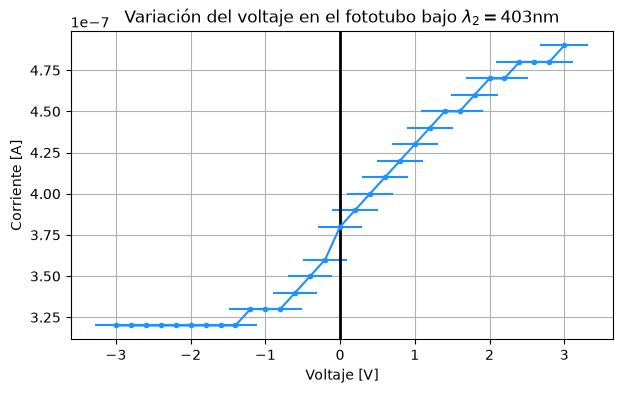

In [16]:
plt.figure(figsize=(7,4))

plt.errorbar(long2_m1_voltaje,long2_m1_corriente,xerr=long2_m1_incVolt,fmt='.-',c='dodgerblue')
plt.title(r'Variación del voltaje en el fototubo bajo $\lambda_2=403$nm')
plt.xlabel(r'Voltaje [V]'), plt.ylabel(r'Corriente [A]')
plt.axvline(x=0, color='black', linewidth=2)
plt.grid()

Buscamos el potencial de frenado como aquel voltaje en donde la corriente comienza a aumentar

In [17]:
for i in range( len(long2_m1_corriente) ):
    if long2_m1_corriente[i+1] > long2_m1_corriente[i]:
        indice = i+1
        print('El índice que corresponde al potencial de frenado es:',indice)
        print(f'Corriente = {long2_m1_corriente[indice]} A')
        print(f'Voltaje de frenado = {long2_m1_voltaje[indice]} ± {long2_m1_incVolt[indice]:.1f} V')
        break

El índice que corresponde al potencial de frenado es: 9
Corriente = 3.3e-07 A
Voltaje de frenado = -1.2 ± 0.3 V


**Gráfica "chida" para el reporte y la expo:**

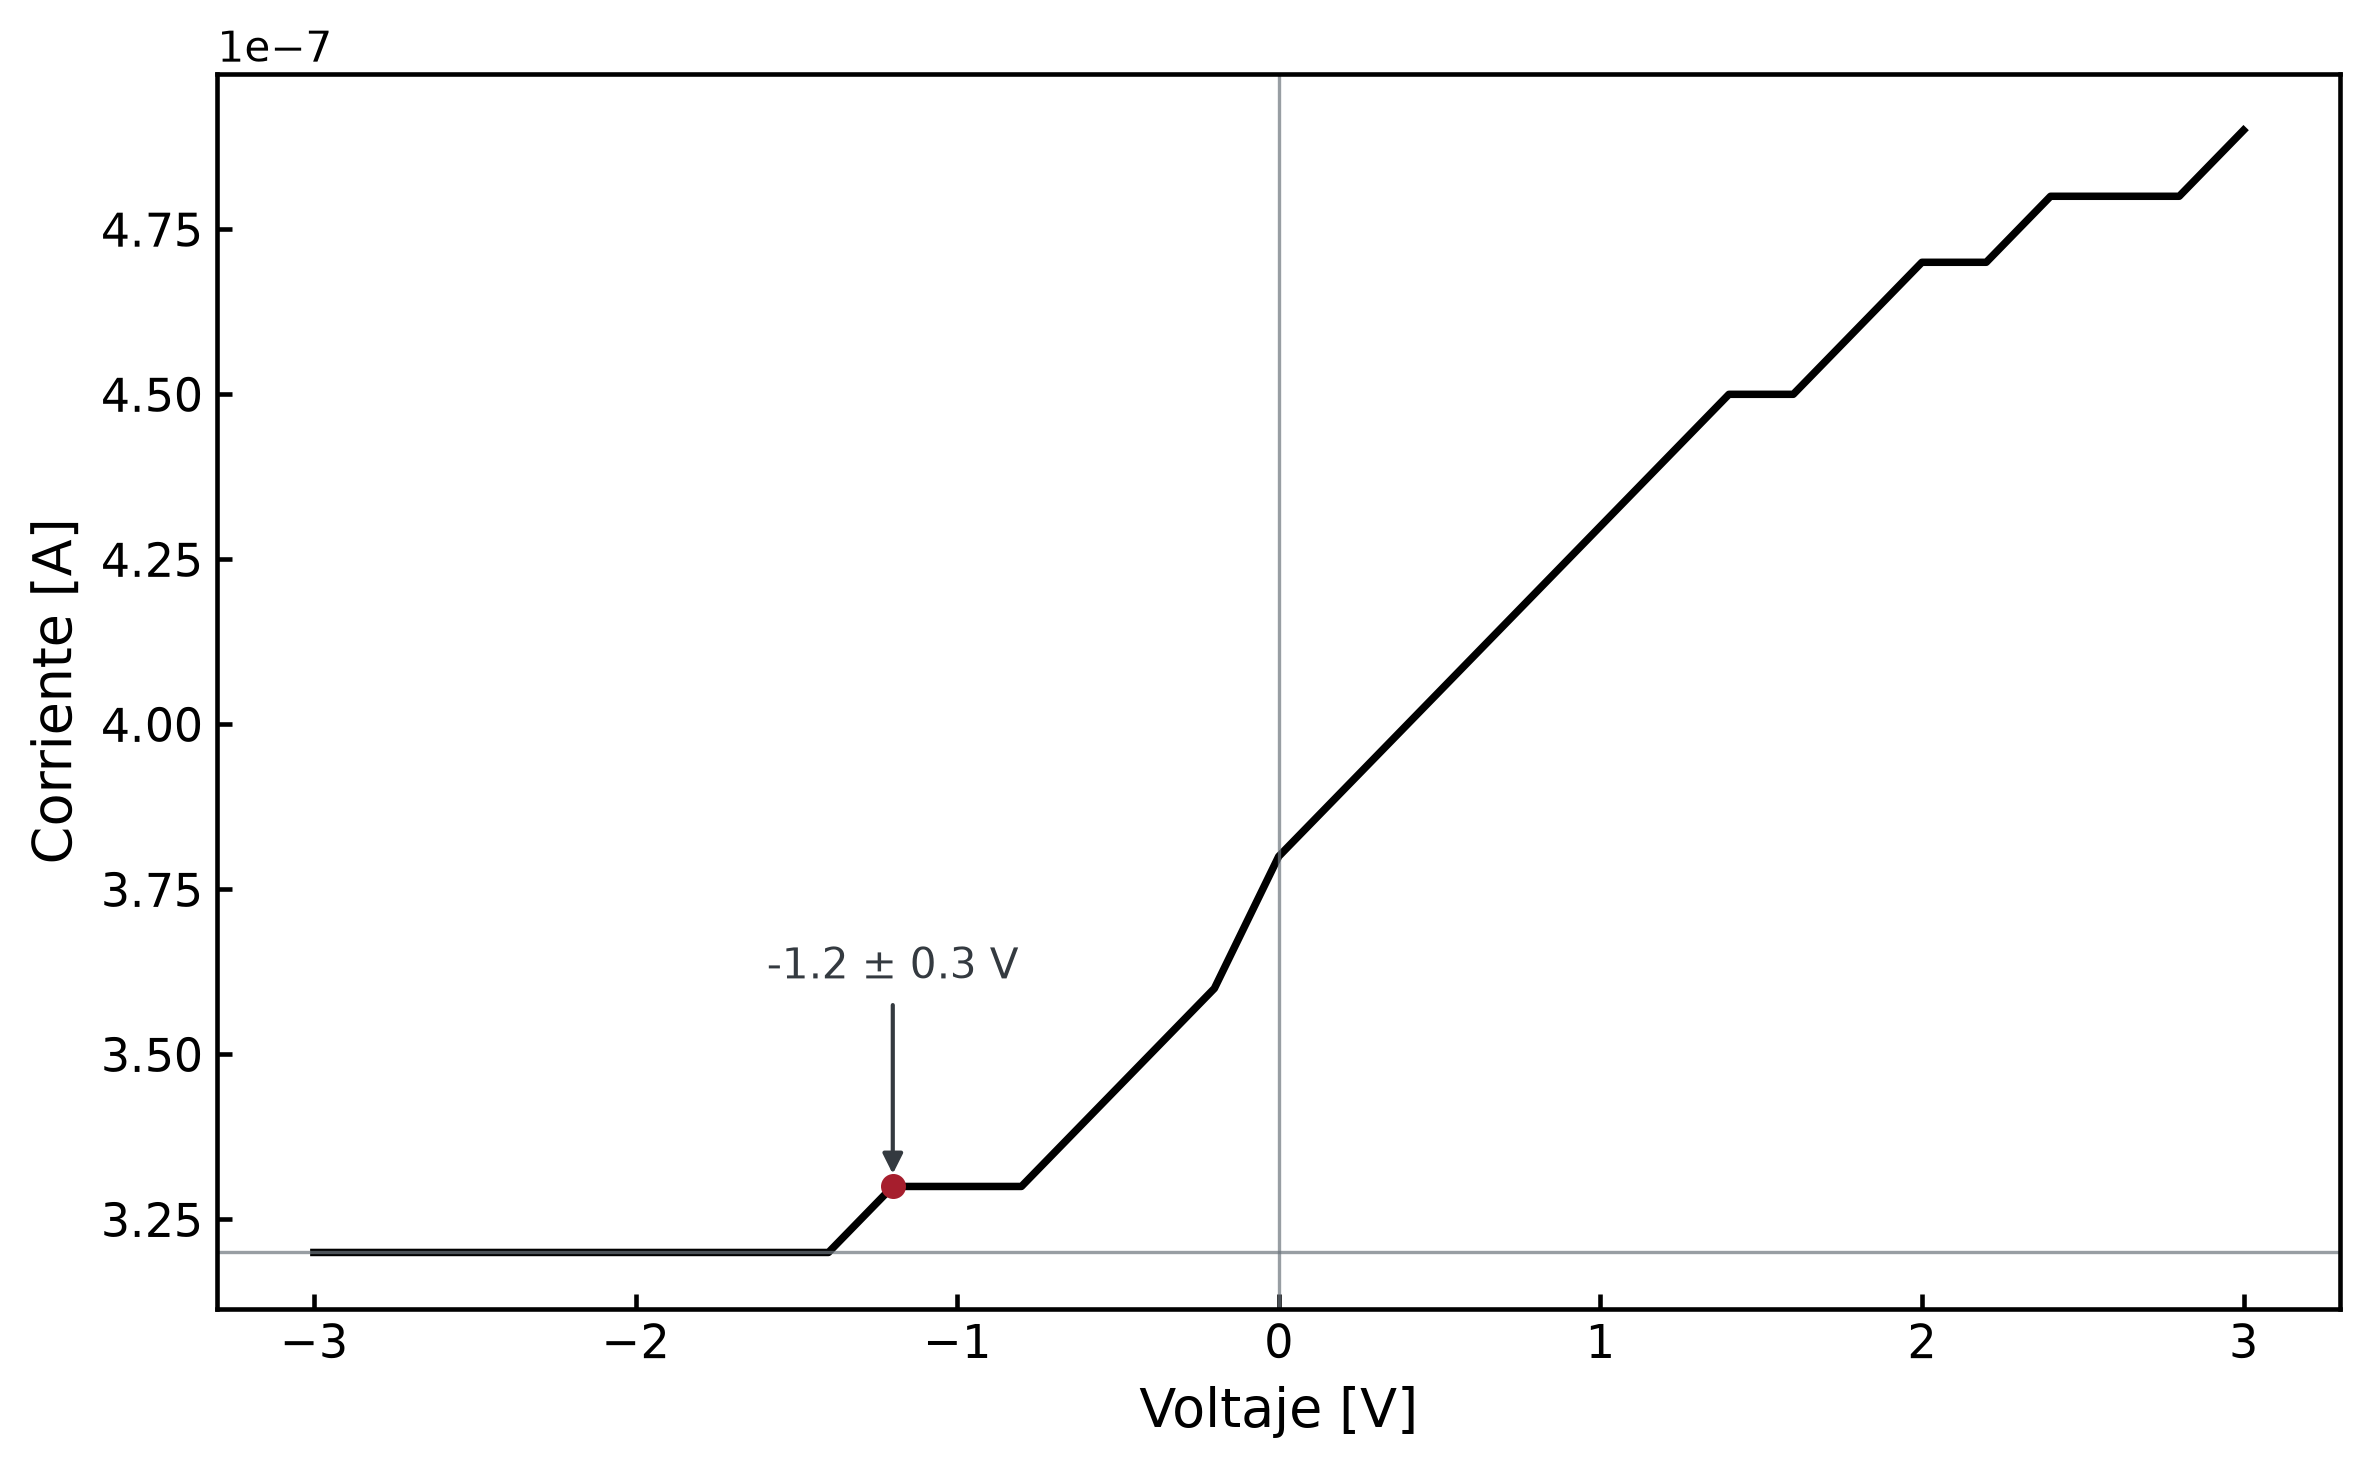

In [18]:
# PRESTAMOS ATENCIÓN PARA HACER REFERENCIA A LA LAMBDA Y EL ÍNDICE CORRECTO
x = long2_m1_voltaje[9]
inc = long2_m1_incVolt[9]
y = long2_m1_corriente[9]

fig, ax = plt.subplots(figsize=(8,5),dpi=300)

# Curva principal
ax.plot(long2_m1_voltaje,long2_m1_corriente,color="black",linewidth=1.8)

# LO QUE SIGUE YA ESTÁ AUTOMATIZADO
# Líneas base
ax.axhline(3.2e-7,color="#6C757D",linewidth=0.8,alpha=0.7)
ax.axvline(0,color="#6C757D",linewidth=0.8,alpha=0.7)

ax.plot(x,y,marker="o",markersize=5,color="#A61E2D",zorder=3)
ax.annotate(fr"{x:.1f} ± {inc:.1f} V",
                xy=(x,y),xytext=(x,y+0.3e-7),ha="center",va="bottom",fontsize=10,
                color="#343A40",arrowprops=dict(arrowstyle="-|>",color="#343A40",lw=1.0,shrinkA=2,shrinkB=3))

# Diseño de los ejes
ax.tick_params(direction="in",labelsize=11,width=1.1)
for borde in ax.spines.values():
    borde.set_linewidth(1.1)
ax.set_xlabel(r"Voltaje [V]",fontsize=13)
ax.set_ylabel("Corriente [A]",fontsize=13)

# Rango de la gráfica
#ax.set_xlim(0,1)
#ax.set_ylim(3e-7, 6.1e-7)

plt.tight_layout()
plt.show()

<hr style="border: 2px solid #000;">

#### $\lambda_3 = 436 \text{ nm } \rightarrow \nu_3 = 6.87597381\times 10^{14} \text{ Hz}$

In [19]:
# Leemos el archivo con los datos
long3_m1 = pd.read_csv("Lambda_3-voltaje_corriente.csv",sep=',',skiprows=1,header=None,dtype='float',usecols=[0,1,2])

# Imprimimos los datos
long3_m1

,0,1,2
0,-3.0,0.276,3.200000e-07
1,-2.8,0.278,3.200000e-07
2,-2.6,0.279,3.200000e-07
3,-2.4,0.281,3.200000e-07
4,-2.2,0.282,3.200000e-07
5,-2.0,0.284,3.200000e-07
6,-1.8,0.286,3.300000e-07
7,-1.6,0.287,3.300000e-07
8,-1.4,0.289,3.300000e-07
9,-1.2,0.290,3.400000e-07


In [20]:
# Nombramos las columnas
long3_m1.columns = (["x","z","y"])

# Guardamos los valores de cada columna en listas para graficar más fácil
long3_m1_voltaje = long3_m1["x"].values
long3_m1_incVolt = long3_m1["z"].values
long3_m1_corriente = long3_m1["y"].values

**Hacemos una gráfica inicial de los datos obtenidos**

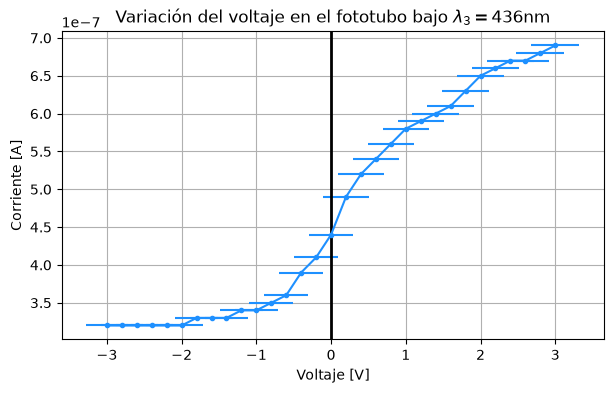

In [21]:
plt.figure(figsize=(7,4))

plt.errorbar(long3_m1_voltaje,long3_m1_corriente,xerr=long3_m1_incVolt,fmt='.-',c='dodgerblue')
plt.title(r'Variación del voltaje en el fototubo bajo $\lambda_3=436$nm')
plt.xlabel(r'Voltaje [V]'), plt.ylabel(r'Corriente [A]')
plt.axvline(x=0, color='black', linewidth=2)
plt.grid()

Buscamos el potencial de frenado como aquel voltaje en donde la corriente comienza a aumentar

In [22]:
for i in range( len(long3_m1_corriente) ):
    if long3_m1_corriente[i+1] > long3_m1_corriente[i]:
        indice = i+1
        print('El índice que corresponde al potencial de frenado es:',indice)
        print(f'Corriente = {long3_m1_corriente[indice]} A')
        print(f'Voltaje de frenado = {long3_m1_voltaje[indice]} ± {long3_m1_incVolt[indice]:.1f} V')
        break

El índice que corresponde al potencial de frenado es: 6
Corriente = 3.3e-07 A
Voltaje de frenado = -1.8 ± 0.3 V


**Gráfica "chida" para el reporte y la expo:**

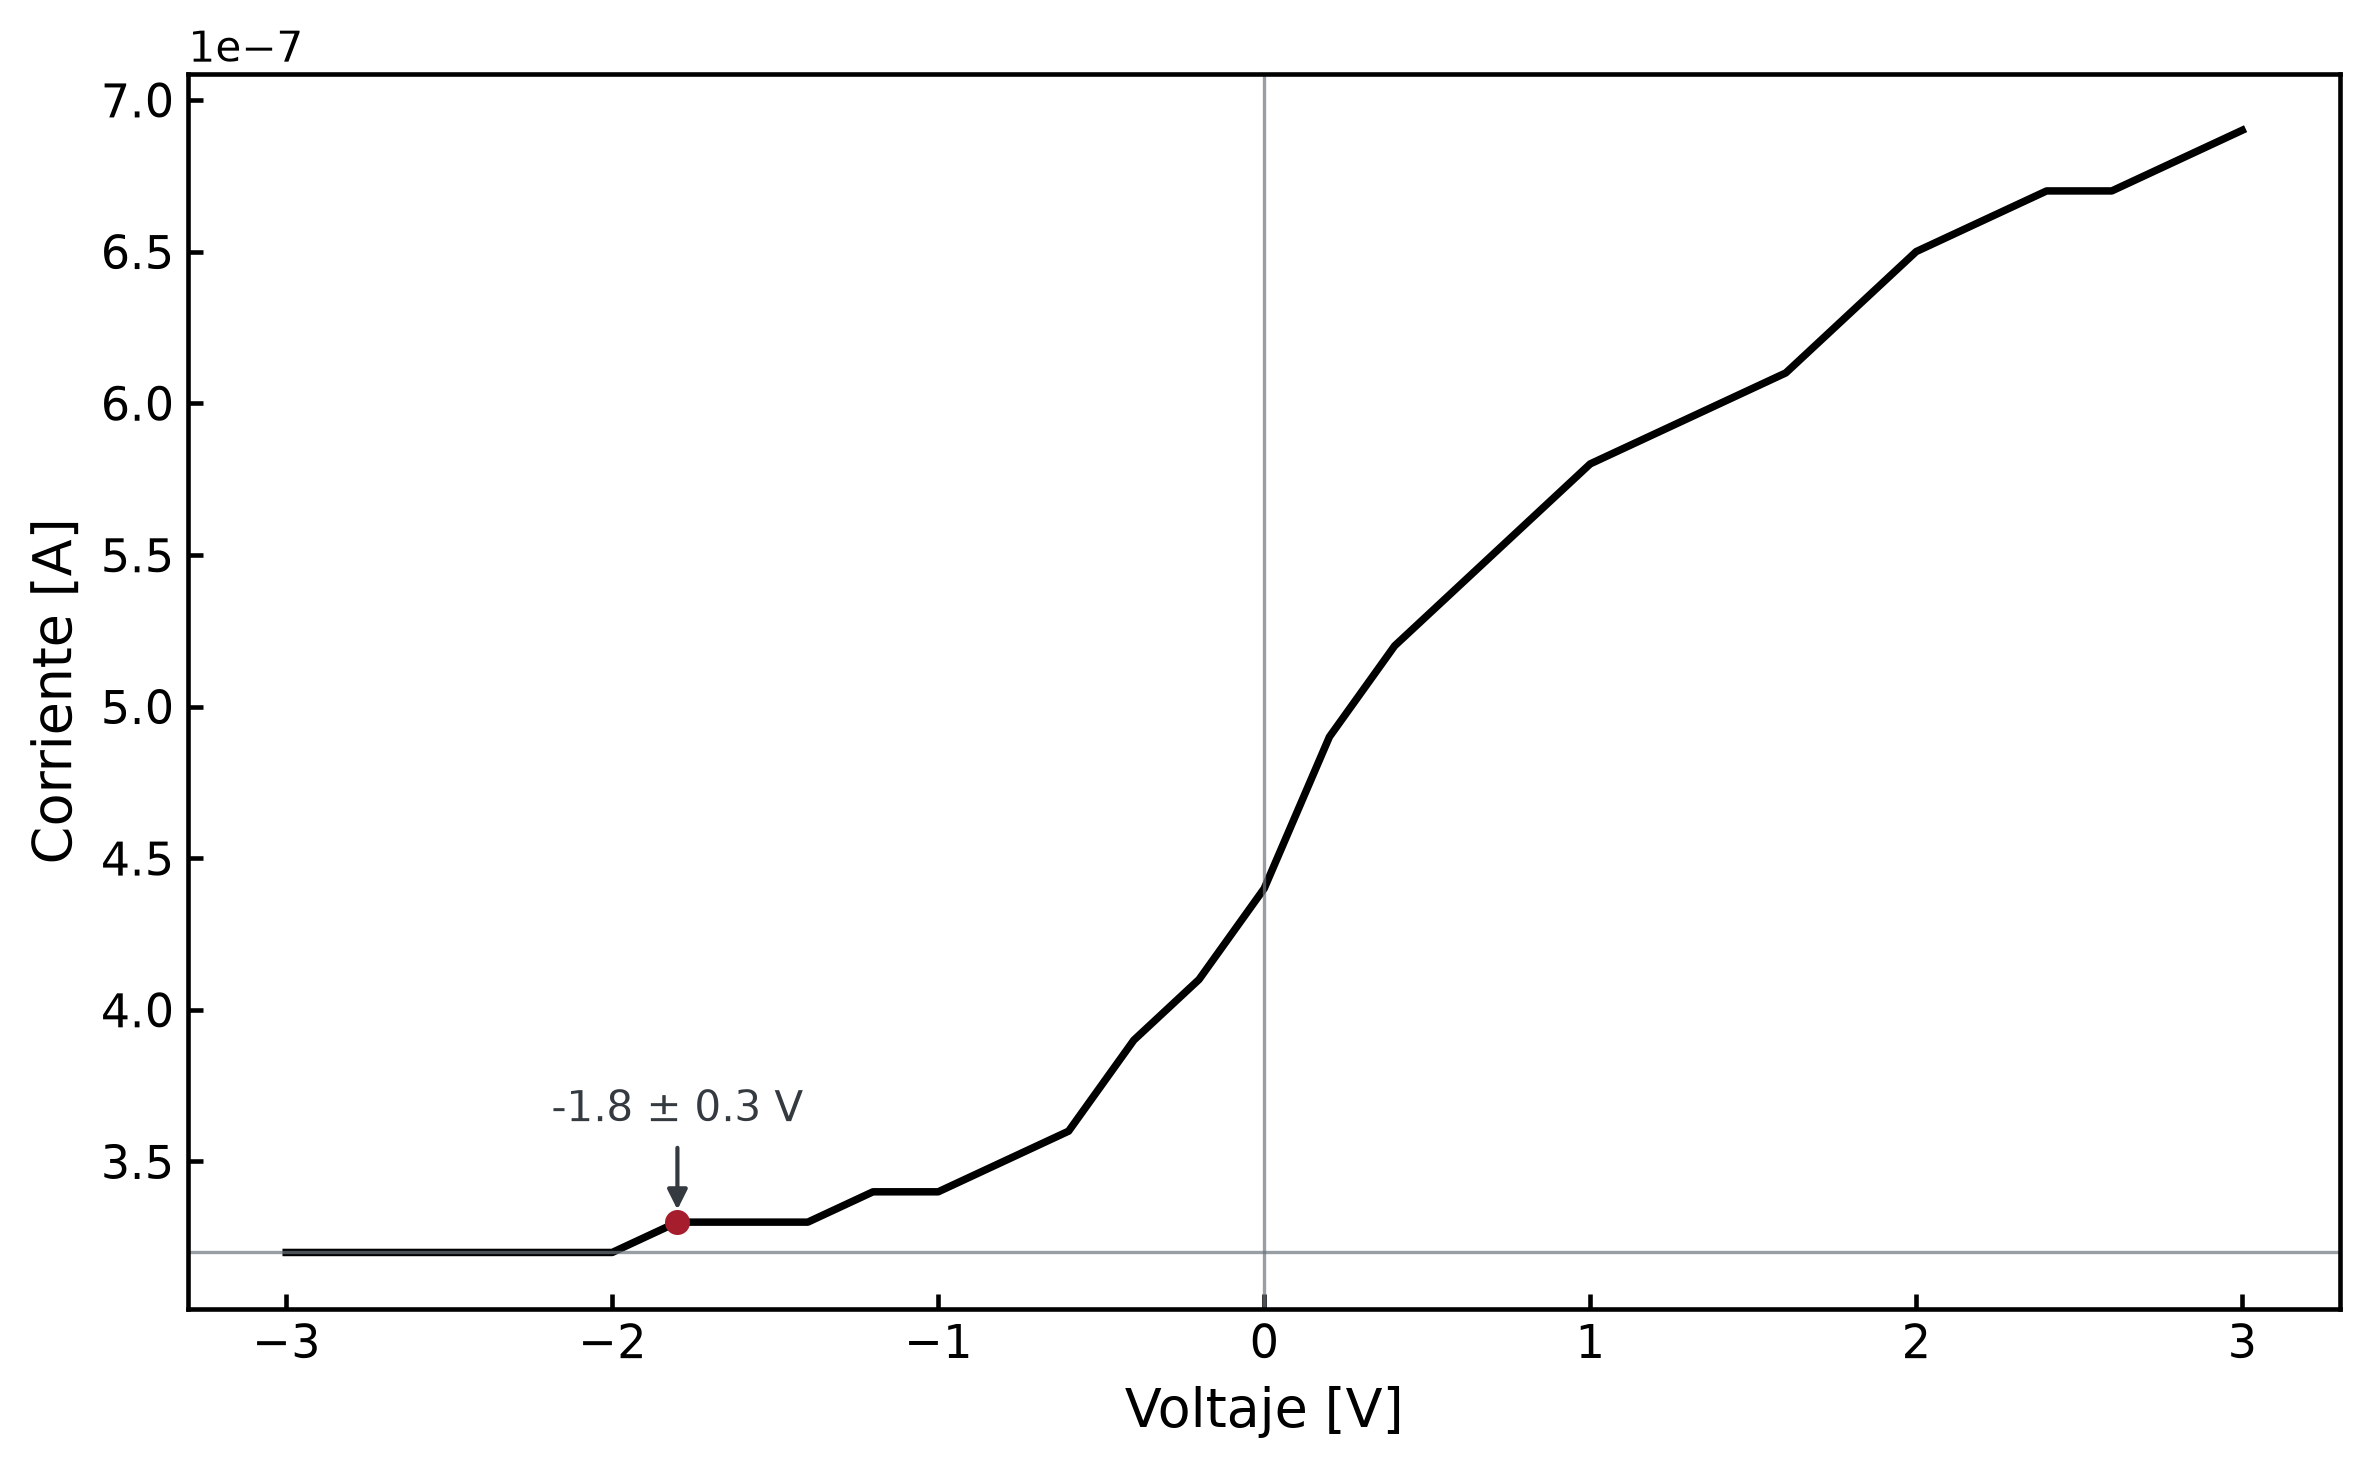

In [23]:
# PRESTAMOS ATENCIÓN PARA HACER REFERENCIA A LA LAMBDA Y EL ÍNDICE CORRECTO
x = long3_m1_voltaje[6]
inc = long3_m1_incVolt[6]
y = long3_m1_corriente[6]

fig, ax = plt.subplots(figsize=(8,5),dpi=300)

# Curva principal
ax.plot(long3_m1_voltaje,long3_m1_corriente,color="black",linewidth=1.8)

# LO QUE SIGUE YA ESTÁ AUTOMATIZADO
# Líneas base
ax.axhline(3.2e-7,color="#6C757D",linewidth=0.8,alpha=0.7)
ax.axvline(0,color="#6C757D",linewidth=0.8,alpha=0.7)

ax.plot(x,y,marker="o",markersize=5,color="#A61E2D",zorder=3)
ax.annotate(fr"{x:.1f} ± {inc:.1f} V",
                xy=(x,y),xytext=(x,y+0.3e-7),ha="center",va="bottom",fontsize=10,
                color="#343A40",arrowprops=dict(arrowstyle="-|>",color="#343A40",lw=1.0,shrinkA=2,shrinkB=3))

# Diseño de los ejes
ax.tick_params(direction="in",labelsize=11,width=1.1)
for borde in ax.spines.values():
    borde.set_linewidth(1.1)
ax.set_xlabel(r"Voltaje [V]",fontsize=13)
ax.set_ylabel("Corriente [A]",fontsize=13)

# Rango de la gráfica
#ax.set_xlim(0,1)
#ax.set_ylim(3e-7, 6.1e-7)

plt.tight_layout()
plt.show()

<hr style="border: 2px solid #000;">

#### $\lambda_4 = 546 \text{ nm } \rightarrow \nu_4 = 8.5.49070436\times 10^{14} \text{ Hz}$

In [24]:
# Leemos el archivo con los datos
long4_m1 = pd.read_csv("Lambda_4-voltaje_corriente.csv",sep=',',skiprows=1,header=None,dtype='float',usecols=[0,1,2])

# Imprimimos los datos
long4_m1

,0,1,2
0,-3.0,0.276,3.200000e-07
1,-2.8,0.278,3.200000e-07
2,-2.6,0.279,3.200000e-07
3,-2.4,0.281,3.300000e-07
4,-2.2,0.282,3.300000e-07
5,-2.0,0.284,3.300000e-07
6,-1.8,0.286,3.400000e-07
7,-1.6,0.287,3.400000e-07
8,-1.4,0.289,3.500000e-07
9,-1.2,0.290,3.500000e-07


In [25]:
# Nombramos las columnas
long4_m1.columns = (["x","z","y"])

# Guardamos los valores de cada columna en listas para graficar más fácil
long4_m1_voltaje = long4_m1["x"].values
long4_m1_incVolt = long4_m1["z"].values
long4_m1_corriente = long4_m1["y"].values

**Hacemos una gráfica inicial de los datos obtenidos**

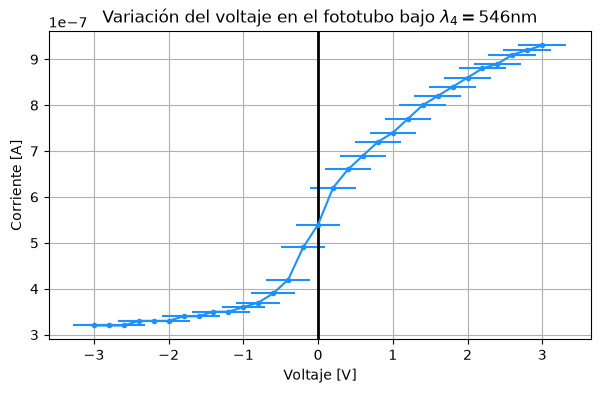

In [26]:
plt.figure(figsize=(7,4))

plt.errorbar(long4_m1_voltaje,long4_m1_corriente,xerr=long4_m1_incVolt,fmt='.-',c='dodgerblue')
plt.title(r'Variación del voltaje en el fototubo bajo $\lambda_4=546$nm')
plt.xlabel(r'Voltaje [V]'), plt.ylabel(r'Corriente [A]')
plt.axvline(x=0, color='black', linewidth=2)
plt.grid()

Buscamos el potencial de frenado como aquel voltaje en donde la corriente comienza a aumentar

In [27]:
for i in range( len(long4_m1_corriente) ):
    if long4_m1_corriente[i+1] > long4_m1_corriente[i]:
        indice = i+1
        print('El índice que corresponde al potencial de frenado es:',indice)
        print(f'Corriente = {long4_m1_corriente[indice]} A')
        print(f'Voltaje de frenado = {long4_m1_voltaje[indice]} ± {long4_m1_incVolt[indice]:.1f} V')
        break

El índice que corresponde al potencial de frenado es: 3
Corriente = 3.3e-07 A
Voltaje de frenado = -2.4 ± 0.3 V


**Gráfica "chida" para el reporte y la expo:**

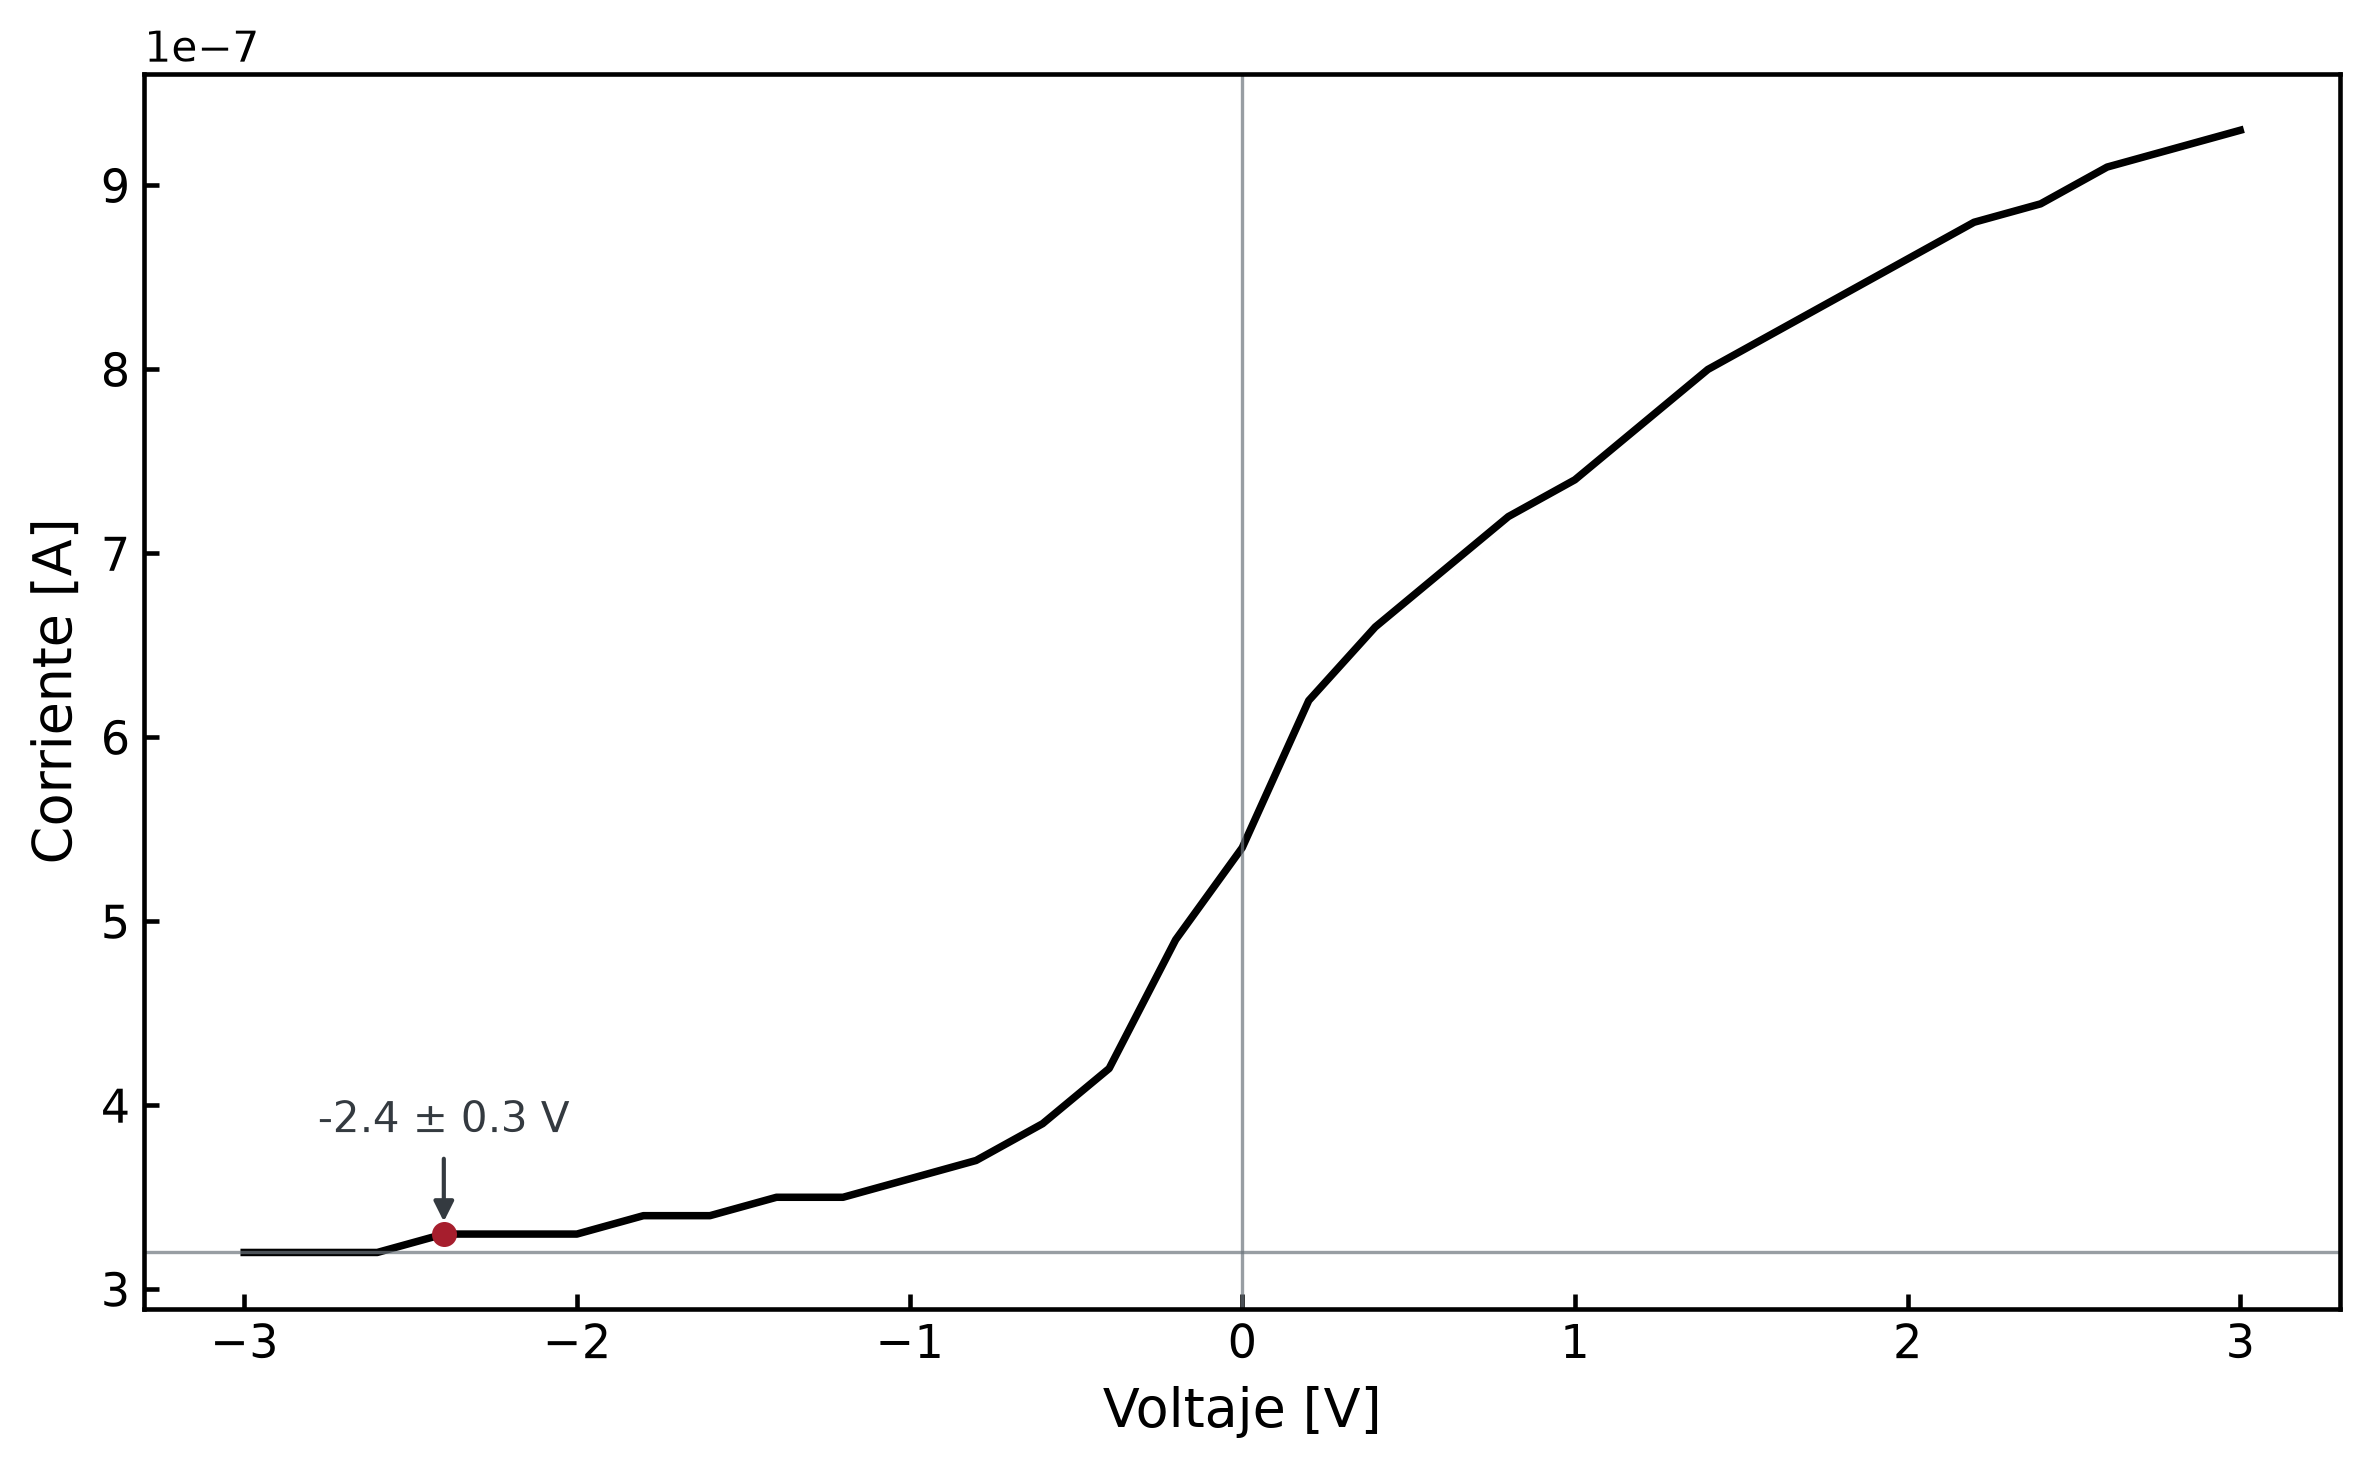

In [28]:
# PRESTAMOS ATENCIÓN PARA HACER REFERENCIA A LA LAMBDA Y EL ÍNDICE CORRECTO
x = long4_m1_voltaje[3]
inc = long4_m1_incVolt[3]
y = long4_m1_corriente[3]

fig, ax = plt.subplots(figsize=(8,5),dpi=300)

# Curva principal
ax.plot(long4_m1_voltaje,long4_m1_corriente,color="black",linewidth=1.8)

# LO QUE SIGUE YA ESTÁ AUTOMATIZADO
# Líneas base
ax.axhline(3.2e-7,color="#6C757D",linewidth=0.8,alpha=0.7)
ax.axvline(0,color="#6C757D",linewidth=0.8,alpha=0.7)

ax.plot(x,y,marker="o",markersize=5,color="#A61E2D",zorder=3)
ax.annotate(fr"{x:.1f} ± {inc:.1f} V",
                xy=(x,y),xytext=(x,y+0.5e-7),ha="center",va="bottom",fontsize=10,
                color="#343A40",arrowprops=dict(arrowstyle="-|>",color="#343A40",lw=1.0,shrinkA=2,shrinkB=3))

# Diseño de los ejes
ax.tick_params(direction="in",labelsize=11,width=1.1)
for borde in ax.spines.values():
    borde.set_linewidth(1.1)
ax.set_xlabel(r"Voltaje [V]",fontsize=13)
ax.set_ylabel("Corriente [A]",fontsize=13)

# Rango de la gráfica
#ax.set_xlim(0,1)
#ax.set_ylim(3e-7, 6.1e-7)

plt.tight_layout()
plt.show()

<hr style="border: 2px solid #000;">

#### $\lambda_5 = 578 \text{ nm } \rightarrow \nu_5 = 5.18672073\times 10^{14} \text{ Hz}$

In [29]:
# Leemos el archivo con los datos
long5_m1 = pd.read_csv("Lambda_5-voltaje_corriente.csv",sep=',',skiprows=1,header=None,dtype='float',usecols=[0,1,2])

# Imprimimos los datos
long5_m1

,0,1,2
0,-3.0,0.276,3.200000e-07
1,-2.8,0.278,3.200000e-07
2,-2.6,0.279,3.200000e-07
3,-2.4,0.281,3.200000e-07
4,-2.2,0.282,3.200000e-07
5,-2.0,0.284,3.200000e-07
6,-1.8,0.286,3.300000e-07
7,-1.6,0.287,3.300000e-07
8,-1.4,0.289,3.300000e-07
9,-1.2,0.290,3.300000e-07


In [30]:
# Nombramos las columnas
long5_m1.columns = (["x","z","y"])

# Guardamos los valores de cada columna en listas para graficar más fácil
long5_m1_voltaje = long5_m1["x"].values
long5_m1_incVolt = long5_m1["z"].values
long5_m1_corriente = long5_m1["y"].values

**Hacemos una gráfica inicial de los datos obtenidos**

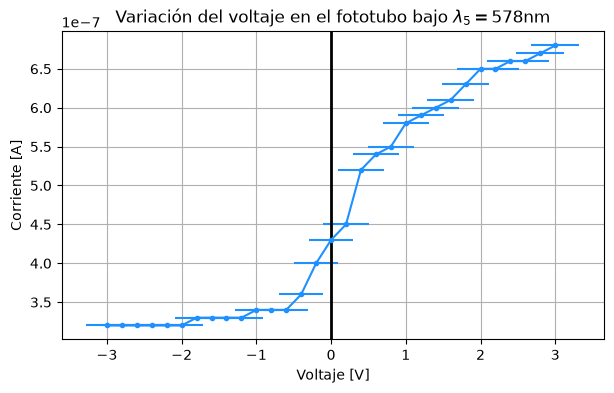

In [31]:
plt.figure(figsize=(7,4))

plt.errorbar(long5_m1_voltaje,long5_m1_corriente,xerr=long5_m1_incVolt,fmt='.-',c='dodgerblue')
plt.title(r'Variación del voltaje en el fototubo bajo $\lambda_5=578$nm')
plt.xlabel(r'Voltaje [V]'), plt.ylabel(r'Corriente [A]')
plt.axvline(x=0, color='black', linewidth=2)
plt.grid()

Buscamos el potencial de frenado como aquel voltaje en donde la corriente comienza a aumentar

In [32]:
for i in range( len(long5_m1_corriente) ):
    if long5_m1_corriente[i+1] > long5_m1_corriente[i]:
        indice = i+1
        print('El índice que corresponde al potencial de frenado es:',indice)
        print(f'Corriente = {long5_m1_corriente[indice]} A')
        print(f'Voltaje de frenado = {long5_m1_voltaje[indice]} ± {long5_m1_incVolt[indice]:.1f} V')
        break

El índice que corresponde al potencial de frenado es: 6
Corriente = 3.3e-07 A
Voltaje de frenado = -1.8 ± 0.3 V


**Gráfica "chida" para el reporte y la expo:**

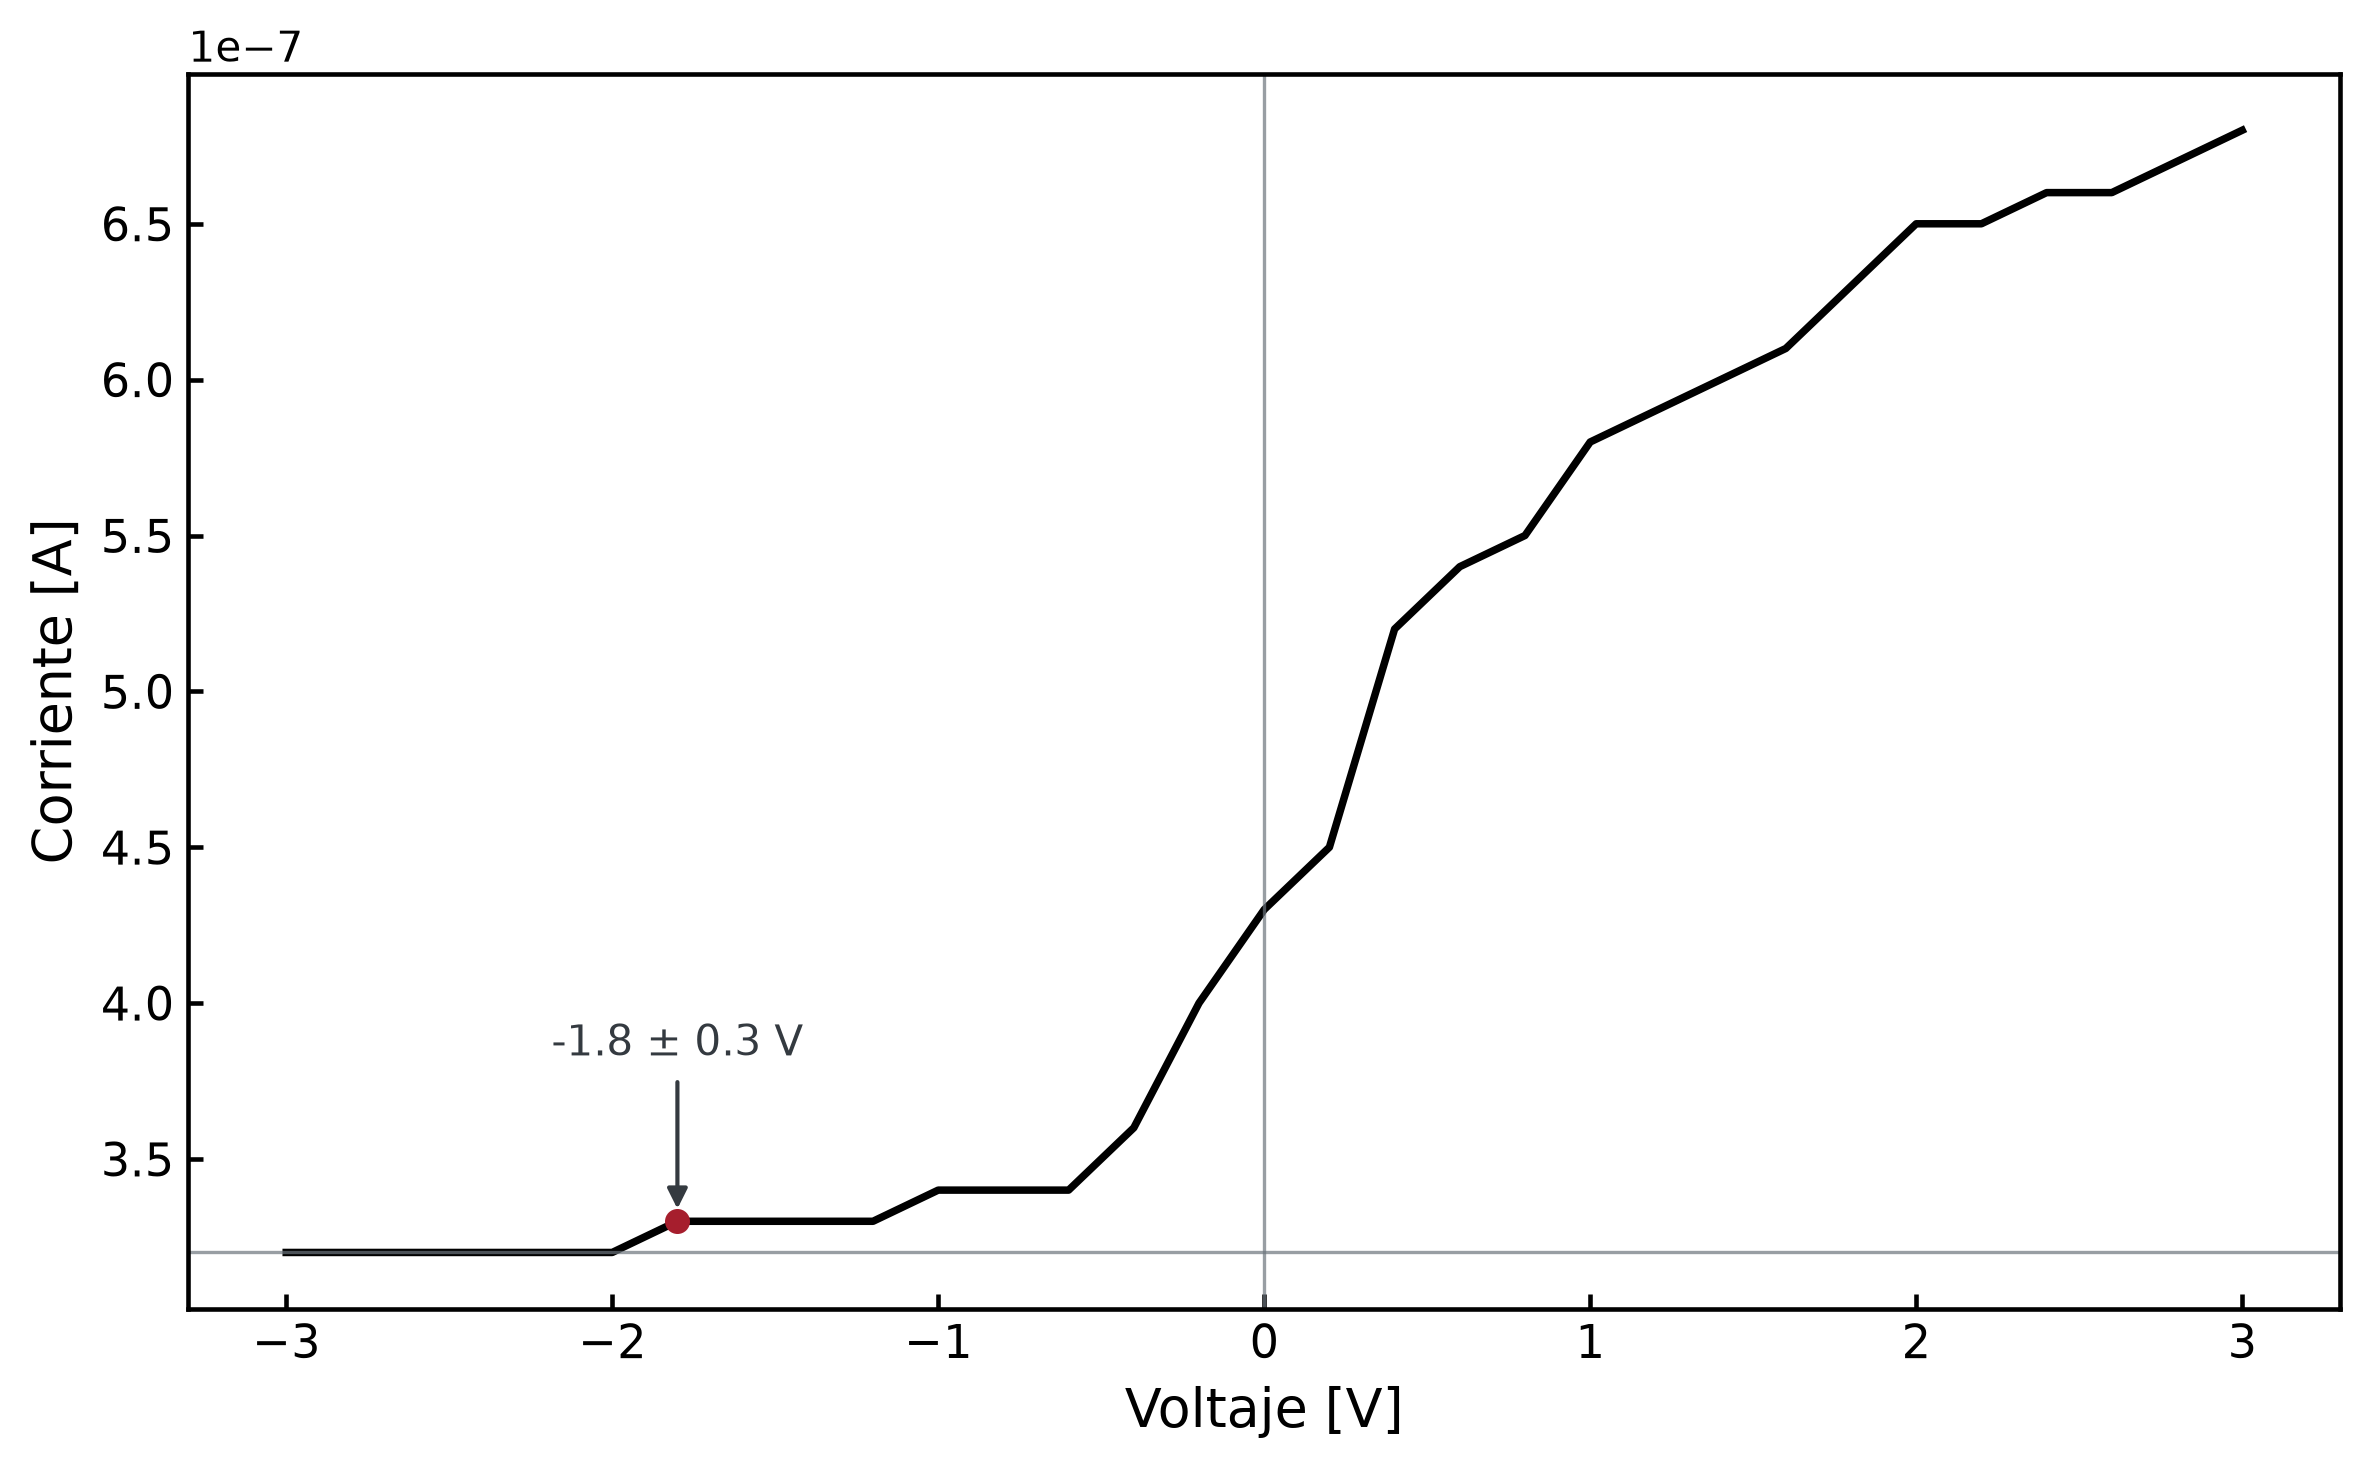

In [33]:
# PRESTAMOS ATENCIÓN PARA HACER REFERENCIA A LA LAMBDA Y EL ÍNDICE CORRECTO
x = long5_m1_voltaje[6]
inc = long5_m1_incVolt[6]
y = long5_m1_corriente[6]

fig, ax = plt.subplots(figsize=(8,5),dpi=300)

# Curva principal
ax.plot(long5_m1_voltaje,long5_m1_corriente,color="black",linewidth=1.8)

# LO QUE SIGUE YA ESTÁ AUTOMATIZADO
# Líneas base
ax.axhline(3.2e-7,color="#6C757D",linewidth=0.8,alpha=0.7)
ax.axvline(0,color="#6C757D",linewidth=0.8,alpha=0.7)

ax.plot(x,y,marker="o",markersize=5,color="#A61E2D",zorder=3)
ax.annotate(fr"{x:.1f} ± {inc:.1f} V",
                xy=(x,y),xytext=(x,y+0.5e-7),ha="center",va="bottom",fontsize=10,
                color="#343A40",arrowprops=dict(arrowstyle="-|>",color="#343A40",lw=1.0,shrinkA=2,shrinkB=3))

# Diseño de los ejes
ax.tick_params(direction="in",labelsize=11,width=1.1)
for borde in ax.spines.values():
    borde.set_linewidth(1.1)
ax.set_xlabel(r"Voltaje [V]",fontsize=13)
ax.set_ylabel("Corriente [A]",fontsize=13)

# Rango de la gráfica
#ax.set_xlim(0,1)
#ax.set_ylim(3e-7, 6.1e-7)

plt.tight_layout()
plt.show()

<hr style="border: 5px solid #000;">

# Constante de Planck
(Graficamos la frecuencia a la que estaba la onda vs. los potenciales de frenado que obtuvimos, hacemos una regresión lineal y despejamos la pendiente para obtener h)

In [34]:
# Estos son los valores que vamos a usar:
potenciales = [-0.8, -1.2, -1.8, -2.4, -1.8]
inc_pot = [0.3, 0.3, 0.3, 0.3, 0.3]

print('Recordamos las frecuencias:',frecuencias,'Hz')

h = constants.h
e = constants.e
print('Valor de la constante de Planck (h):',h,'J⋅s')
print('Valor de la carga del electrón (e):',e,'C')

Recordamos las frecuencias: [8.21349200e+14 7.43901881e+14 6.87597381e+14 5.49070436e+14
 5.18672073e+14] Hz
Valor de la constante de Planck (h): 6.62607015e-34 J⋅s
Valor de la carga del electrón (e): 1.602176634e-19 C


**Hacemos una gráfica inicial de los datos**

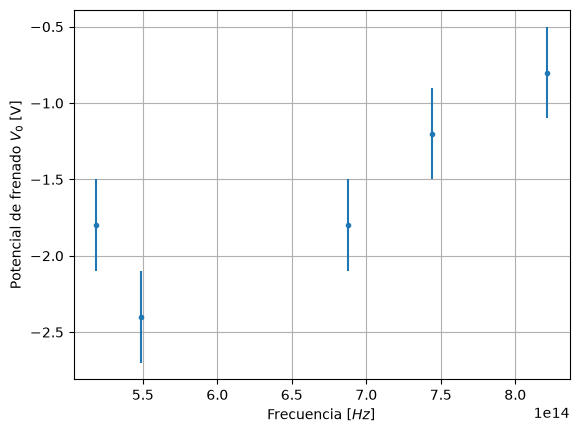

In [35]:
plt.errorbar(frecuencias,potenciales,yerr=inc_pot,fmt='.')
plt.xlabel(r'Frecuencia [$Hz$]'), plt.ylabel(r'Potencial de frenado $V_0$ [V]')
plt.grid()
plt.show()

Hacemos la regresión lineal (usando sklearn)

**NOTA**: ignoramos el primer punto (el que está hasta la izquierda) ya que no sigue el comportamiento de los demás. Por eso tomamos el rango [ :-1].

In [36]:
frecuencias_reshape = np.array(frecuencias[:-1]).reshape(-1,1) # Reescalamos 'potenciales' porque en X se necesita un arreglo 2D

model = LinearRegression() # Invocamos al modelo
model.fit(frecuencias_reshape, potenciales[:-1], sample_weight=1/np.array(inc_pot[:-1])**2) # Entrenamos al modelo

potenciales_reg = model.predict(frecuencias_reshape) # Hacemos las predicciones (la regresión lineal
                                                     # para las frecuencias como función de los potenciales)

m = model.coef_[0] # m: pendiente (h/e)
b = model.intercept_ # b: ordenada al origen
print('La ecuación de la recta de tendencia es: y =',m,'x +',b)

pesos = 1/np.array(inc_pot[:-1])**2
frec_prom = np.average(frecuencias[:-1],weights=pesos)
inc_m = np.sqrt(1/np.sum(pesos*(np.array(frecuencias[:-1])-frec_prom)**2))
print('Con una incertiumbre en la pendiente (m) de:',inc_m)

La ecuación de la recta de tendencia es: y = 6.006428978570498e-15 x + -5.7573817154241365
Con una incertiumbre en la pendiente (m) de: 1.507830113664885e-15


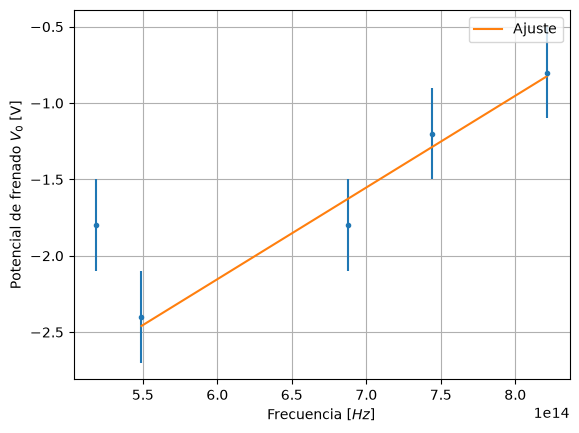

In [37]:
plt.errorbar(frecuencias,potenciales,yerr=inc_pot,fmt='.')
plt.plot(frecuencias[:-1],potenciales_reg,label='Ajuste')
plt.xlabel(r'Frecuencia [$Hz$]'), plt.ylabel(r'Potencial de frenado $V_0$ [V]')
plt.legend()
plt.grid()
plt.show()

Despejamos ahora sí la constante de Planck (h).

En esta relación Frecuencia vs. Potencial de frenado la pendiente es igual a

$ m = \frac{h}{e} \Rightarrow h = me $

In [50]:
h_experimental = m*e
inc_h = inc_m*e

R2 = model.score(frecuencias_reshape, potenciales[:-1])

print('El valor REAL de la constante de Planck (h) es de:',h,'J⋅s')
print(f'mientras que nuestro valor EXPERIMENTAL es de: {h_experimental:.8e} J⋅s')
print(f'con una incertidumbre de: {inc_h:.8e}.')
print(f'Tenemos un error relativo del: {(h_experimental-h)/h:.2f}')
print('y un coeficiente R^2 =', R2,'.')

El valor REAL de la constante de Planck (h) es de: 6.62607015e-34 J⋅s
mientras que nuestro valor EXPERIMENTAL es de: 9.62336016e-34 J⋅s
con una incertidumbre de: 2.41581018e-34.
Tenemos un error relativo del: 0.45
y un coeficiente R^2 = 0.9715229001887852 .


**"Segundo intento" haciendo la regresión con todos los puntos, sin quitar alguno**

In [46]:
frecuencias2_reshape = np.array(frecuencias.reshape(-1,1)) # Reescalamos 'potenciales' porque en X se necesita un arreglo 2D

model2 = LinearRegression() # Invocamos al modelo
model2.fit(frecuencias2_reshape, potenciales, sample_weight=1/np.array(inc_pot)**2) # Entrenamos al modelo

potenciales2_reg = model2.predict(frecuencias2_reshape) # Hacemos las predicciones (la regresión lineal
                                                     # para las frecuencias como función de los potenciales)

m2 = model2.coef_[0] # m: pendiente (h/e)
b2 = model2.intercept_ # b: ordenada al origen
print('La ecuación de la recta de tendencia es: y =',m2,'x +',b2)

pesos2 = 1/np.array(inc_pot)**2
frec_prom2 = np.average(frecuencias,weights=pesos2)
inc_m2 = np.sqrt(1/np.sum(pesos2*(np.array(frecuencias)-frec_prom2)**2))
print('Con una incertiumbre en la pendiente (m) de:',inc_m2)

La ecuación de la recta de tendencia es: y = 4.1516675750449086e-15 x + -4.357197972184151
Con una incertiumbre en la pendiente (m) de: 1.1674931964474495e-15


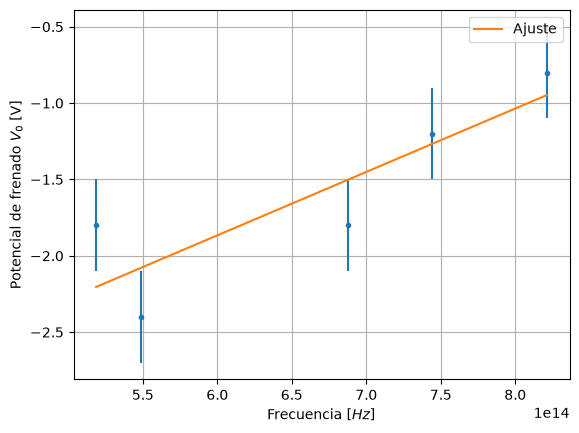

In [47]:
plt.errorbar(frecuencias,potenciales,yerr=inc_pot,fmt='.')
plt.plot(frecuencias,potenciales2_reg,label='Ajuste')
plt.xlabel(r'Frecuencia [$Hz$]'), plt.ylabel(r'Potencial de frenado $V_0$ [V]')
plt.legend()
plt.grid()
plt.show()

In [51]:
h_experimental2 = m2*e
inc_h2 = inc_m2*e

R2_2 = model2.score(frecuencias2_reshape, potenciales)

print('El valor REAL de la constante de Planck (h) es de:',h,'J⋅s')
print(f'mientras que nuestro valor EXPERIMENTAL es de: {h_experimental2:.8e} J⋅s')
print(f'con una incertidumbre de: {inc_h2:.8e}.')
print(f'Tenemos un error relativo del: {(h_experimental2-h)/h:.3f}')
print('y un coeficiente R^2 =',R2_2,'.')

El valor REAL de la constante de Planck (h) es de: 6.62607015e-34 J⋅s
mientras que nuestro valor EXPERIMENTAL es de: 6.65170478e-34 J⋅s
con una incertidumbre de: 1.87053032e-34.
Tenemos un error relativo del: 0.004
y un coeficiente R^2 = 0.748747437446059 .
